# COMP1800 Project: ChrisCo Visual Data Exploration

**Purpose:** This notebook performs a comprehensive visual analysis of visitor and sales data for ChrisCo's 35 venues. It uses standardized Matplotlib plotting techniques to identify trends, demographics, and key performance indicators.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display
import os

# Create plots directory if not exists
if not os.path.exists('plots'):
    os.makedirs('plots')

# Data Loading
try:
    visitors = pd.read_csv('VenueDailyVisitors.csv', index_col=0, parse_dates=True)
    age = pd.read_csv('VenueAge.csv', index_col=0)
    distance = pd.read_csv('VenueDistance.csv', index_col=0)
    duration = pd.read_csv('VenueDuration.csv', index_col=0)
    gender = pd.read_csv('VenueGender.csv', index_col=0)
    spend = pd.read_csv('VenueSpend.csv', index_col=0)
    
    total_v = visitors.sum().rename('Total_Visitors')
    summary_data = pd.concat([age, distance, duration, gender, spend, total_v], axis=1)
    summary_data.columns = ['Age', 'Dist', 'Dur', 'Fem%', 'Spend', 'Total_Visitors']
    
    print("Dataframes successfully initialized.")
except Exception as e:
    print(f"Error loading data: {e}")

Dataframes successfully initialized.


## 1. Proportion Analysis: Venue Volume Ranking

**Purpose:** Numbering and segmenting venues by volume to identify top feeders and low-traffic locations.

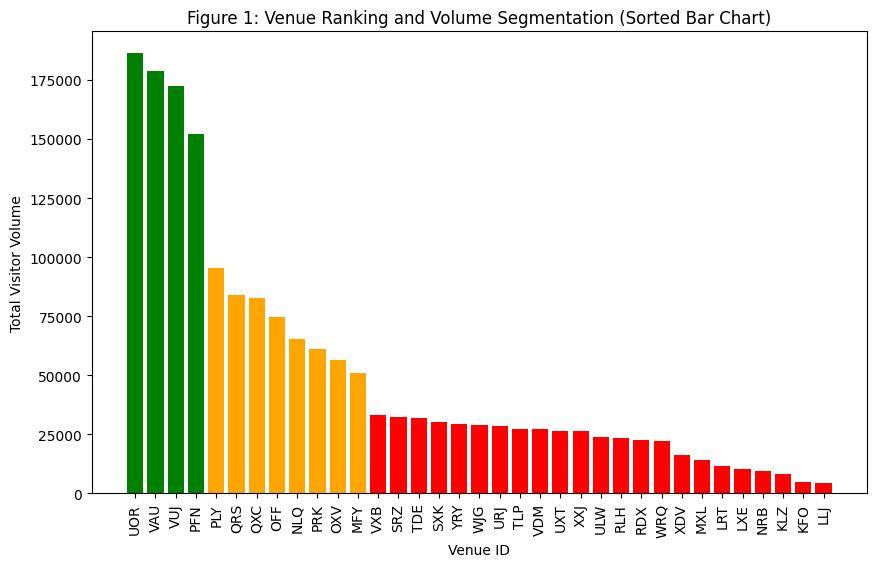

In [13]:
total_visitors = summary_data['Total_Visitors'].sort_values(ascending=False)
plt.figure(figsize=(10, 6))
x_pos = np.arange(len(total_visitors))
colors = ['green']*4 + ['orange']*8 + ['red']*(len(total_visitors)-12) 
plt.bar(x_pos, total_visitors.values, align='center', color=colors)
plt.xticks(x_pos, total_visitors.index, rotation=90)
plt.xlabel('Venue ID')
plt.ylabel('Total Visitor Volume')
plt.title('Figure 1: Venue Ranking and Volume Segmentation (Sorted Bar Chart)')
plt.savefig('plots/v1_bar.png', bbox_inches='tight')
plt.show()

## 2. Dimension Analysis: Multi-Metric Comparative Performance

**Purpose:** Comparing normalized Age, Duration, and Spend metrics to distinguish the operational profiles of high-volume venues.

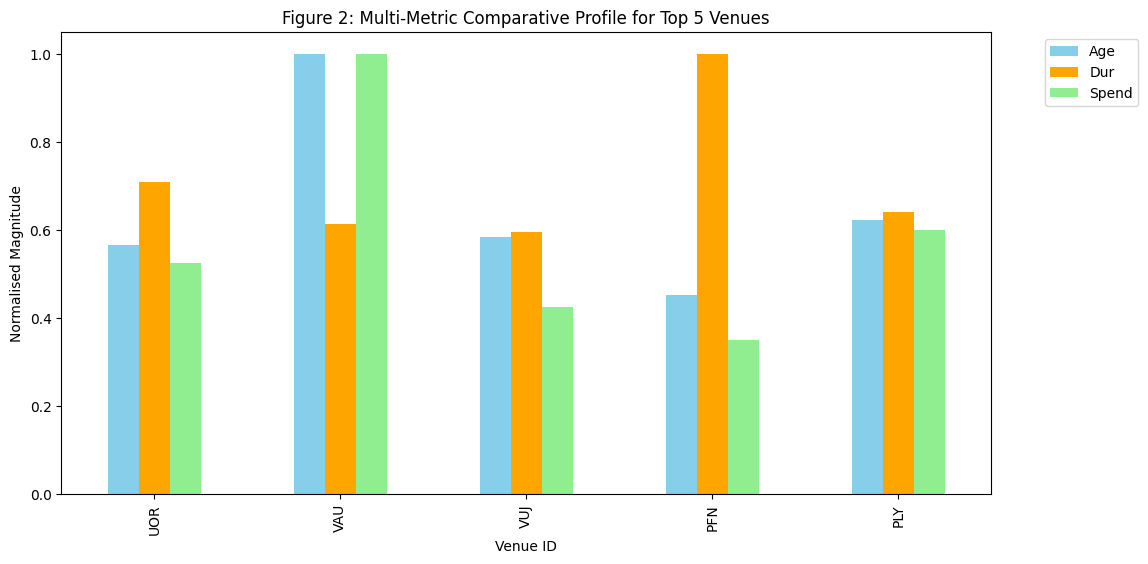

In [14]:
top_5_idx = summary_data['Total_Visitors'].sort_values(ascending=False).head(5).index
norm_subset = summary_data.loc[top_5_idx, ['Age', 'Dur', 'Spend']]
norm_subset = norm_subset / norm_subset.max()

norm_subset.plot(kind='bar', figsize=(12, 6), color=['skyblue', 'orange', 'lightgreen'])
plt.title('Figure 2: Multi-Metric Comparative Profile for Top 5 Venues')
plt.ylabel('Normalised Magnitude')
plt.xlabel('Venue ID')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.savefig('plots/v2_grouped.png', bbox_inches='tight')
plt.show()

## 3. Time Series Trends: Aggregate Market Health

**Purpose:** Visualizing total daily visitors with a moving average to clear daily volatility and reveal aggregate business trends.

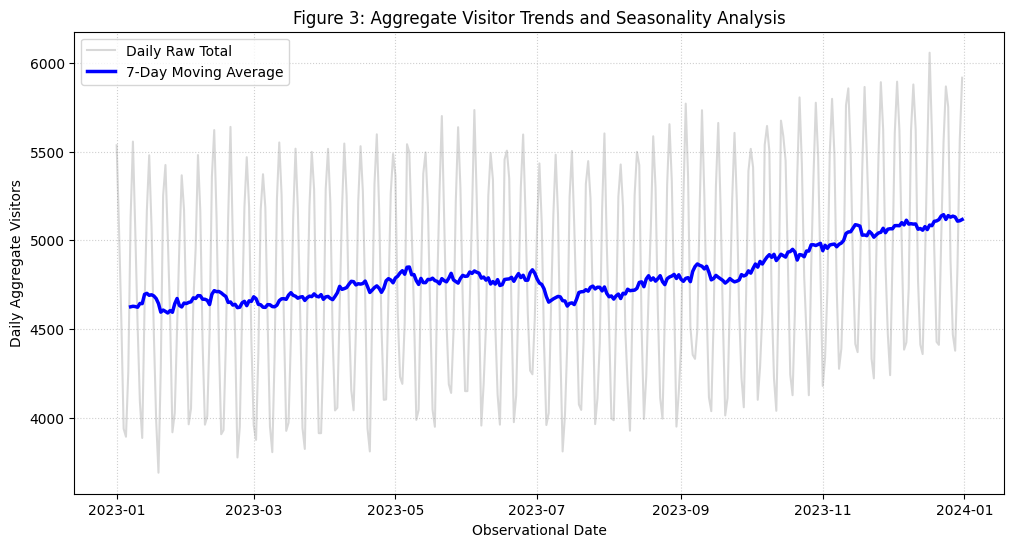

In [15]:
daily_total = visitors.sum(axis=1)
rolling_avg = daily_total.rolling(window=7).mean()
plt.figure(figsize=(12, 6))
plt.plot(daily_total.index, daily_total.values, color='gray', alpha=0.3, label='Daily Raw Total')
plt.plot(rolling_avg.index, rolling_avg.values, color='blue', linewidth=2.5, label='7-Day Moving Average')
plt.xlabel('Observational Date')
plt.ylabel('Daily Aggregate Visitors')
plt.title('Figure 3: Aggregate Visitor Trends and Seasonality Analysis')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.savefig('plots/v3_time.png', bbox_inches='tight')
plt.show()

## 4. Distribution Analysis: Daily Traffic Volatility

**Purpose:** Using Box Plots to analyze the stability and outlier characteristics of visitor flow for the top performing venues.

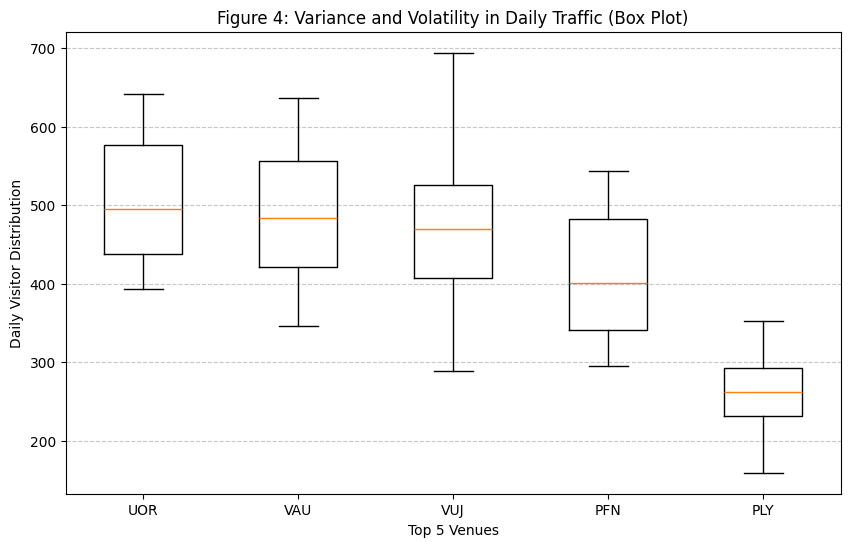

In [16]:
top_5_ids = summary_data['Total_Visitors'].sort_values(ascending=False).head(5).index
plt.figure(figsize=(10, 6))
plt.boxplot([visitors[v_id].dropna() for v_id in top_5_ids], tick_labels=top_5_ids)
plt.xlabel('Top 5 Venues')
plt.ylabel('Daily Visitor Distribution')
plt.title('Figure 4: Variance and Volatility in Daily Traffic (Box Plot)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig('plots/v4_box.png', bbox_inches='tight')
plt.show()

## 5. Correlation Analysis: Demographic Spending Trends

**Purpose:** Calculating the relationship between visitor age and spend using bivariate scatter plots and linear regression.

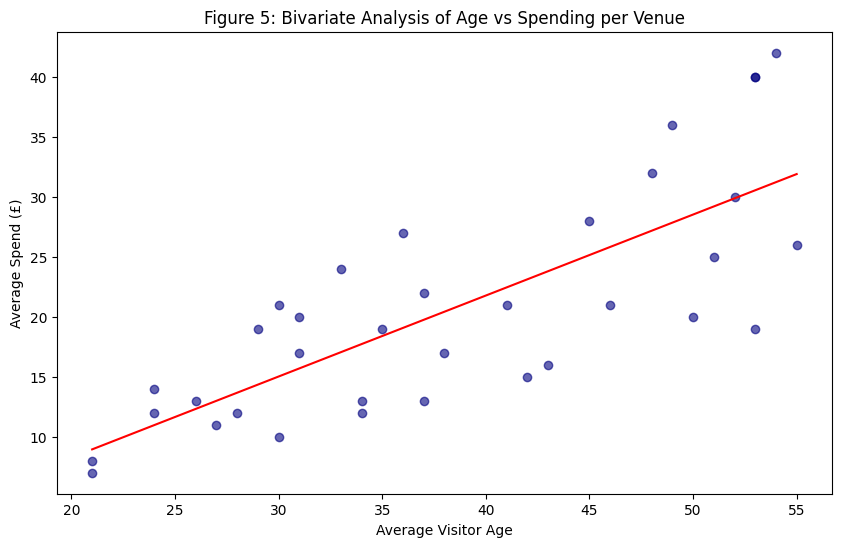

In [17]:
plt.figure(figsize=(10, 6))
plt.scatter(summary_data['Age'], summary_data['Spend'], color='navy', alpha=0.6)
z = np.polyfit(summary_data['Age'], summary_data['Spend'], 1)
p = np.poly1d(z)
plt.plot(sorted(summary_data['Age']), p(sorted(summary_data['Age'])), color='red')
plt.title('Figure 5: Bivariate Analysis of Age vs Spending per Venue')
plt.xlabel('Average Visitor Age')
plt.ylabel('Average Spend (£)')
plt.savefig('plots/v5_scatter.png', bbox_inches='tight')
plt.show()

## 6. Dimensional Profile: Multi-Attribute signatures

**Purpose:** Presenting a radar visualization that identifies the unique characteristic 'signatures' of specific flagship venues.

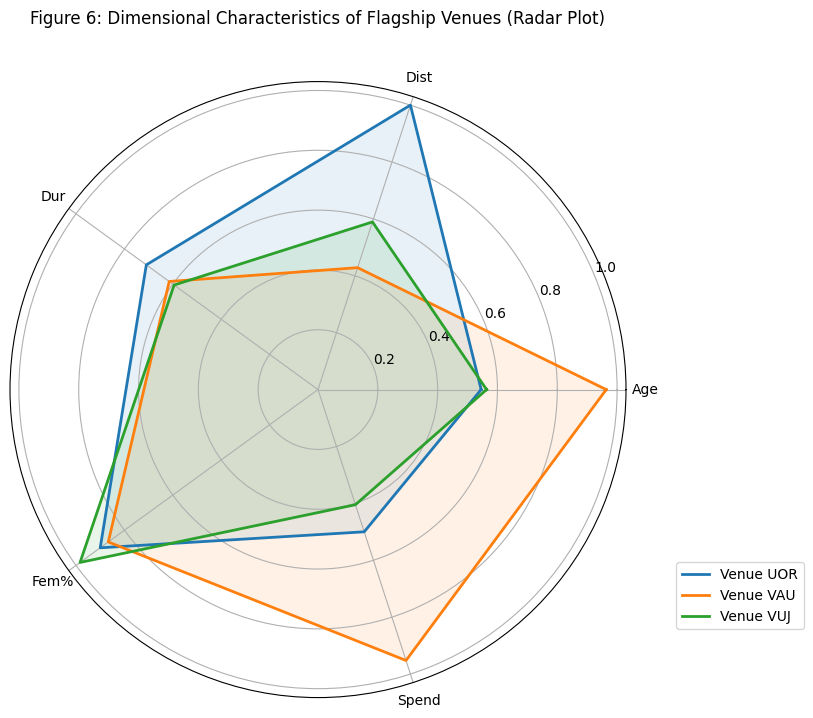

In [18]:
top_3_ids = summary_data['Total_Visitors'].sort_values(ascending=False).head(3).index
radar_df = summary_data.drop(columns=['Total_Visitors'])
norm_radar = radar_df / radar_df.max()
selected_radar = norm_radar.loc[top_3_ids]

n_attr = len(norm_radar.columns)
angles = [n / float(n_attr) * 2 * np.pi for n in range(n_attr + 1)]
plt.figure(figsize=(8, 8))
ax = plt.subplot(111, polar=True)
for i, venue in enumerate(top_3_ids):
    values = selected_radar.loc[venue].tolist()
    values += values[:1]
    ax.plot(angles, values, linewidth=2, label=f'Venue {venue}')
    ax.fill(angles, values, alpha=0.1)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(norm_radar.columns)
plt.title('Figure 6: Dimensional Characteristics of Flagship Venues (Radar Plot)', y=1.08)
plt.legend(loc='lower right', bbox_to_anchor=(1.3, 0.1))
plt.savefig('plots/v6_radar.png', bbox_inches='tight')
plt.show()

## 7. Interactive Exploration: Individual Site Performance

**Purpose:** An interactive drill-down tool allowing for the live inspection of specific venue timelines to identify localized patterns.

In [19]:
def explore_venue(venue_id):
    df = visitors[venue_id]
    plt.figure(figsize=(12, 5))
    plt.plot(df.index, df.values, color='darkgreen')
    plt.title(f'Figure 7: Time Series Drill-Down for Venue {venue_id}')
    plt.show()
widgets.interact(explore_venue, venue_id=sorted(visitors.columns))

interactive(children=(Dropdown(description='venue_id', options=('KFO', 'KLZ', 'LLJ', 'LRT', 'LXE', 'MFY', 'MXL…

<function __main__.explore_venue(venue_id)>

## 8. Interactive Analysis: Demographic Segment Filtering

**Purpose:** A dynamic correlation tool that filters venue data by age threshold to uncover high-value consumer groups.

In [ ]:
def explore_spend_age(min_age):
    filtered = summary_data[summary_data['Age'] >= min_age]
    plt.figure(figsize=(10, 6))
    plt.scatter(filtered['Age'], filtered['Spend'], color='purple')
    plt.xlim(15, 65)
    plt.ylim(0, 100)
    plt.title(f'Figure 8: Spending Correlation Filter (Min Age: {min_age})')
    plt.show()
    
widgets.interact(explore_spend_age, min_age=(18, 60))

interactive(children=(IntSlider(value=39, description='min_age', max=60, min=18), Output()), _dom_classes=('wi…

<function __main__.explore_spend_age(min_age)>